# 04 — Fairness Audit
**Objective 4 of the proposal:** quantify fairness across customer subgroups using established group fairness metrics (demographic parity, equalised odds, disparate impact ratio), and analyse systematic disparities in false-positive and false-negative rates.

**Run notebooks 1–3 first** — this notebook loads their saved predictions, thresholds and SHAP values.

**What is audited.** Both models are audited at their **deployed thresholds** (chosen on month 5 to flag 5% of legitimate applicants), on the test months 6–7, across the three BAF protected attributes: age, income and employment status.

**Why false-positive rates matter most here.** A false positive is a genuine customer whose account application is declined. Differences in false-positive rates between groups are therefore the clearest sign of unequal *harm* — the Consumer Duty's "avoidance of foreseeable harm" outcome. BAF's own benchmark measures fairness the same way ("predictive equality": the ratio of false-positive rates between groups).

**Sections**
1. Who is in each group (sizes and actual fraud rates)
2. Error rates by group, with 95% confidence intervals
3. Summary fairness metrics (Fairlearn)
4. Does the disparity depend on the threshold?
5. Threshold drift by month and group
6. What drives the age gap? (SHAP decomposition)
7. Experiment: retraining **without** the protected attributes

In [1]:
import os
import sys
import gc
import json
import time
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
from fairlearn.metrics import (
    MetricFrame, selection_rate, false_positive_rate, true_positive_rate,
    demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference,
)
from sklearn.metrics import average_precision_score, roc_curve

RANDOM_STATE = 42
TARGET_FPR = 0.05
MIN_GROUP_SIZE = 1_000   # groups smaller than this are shown but left out of the summary metrics

# ---- Work out where the data is, depending on which machine this is running on ----
COLAB_DATA_DIR = '/content/drive/MyDrive/Dissertation/data'   # edit to match your Drive folder

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path(COLAB_DATA_DIR)
    MACHINE = 'Google Colab'
elif os.environ.get('DISSERTATION_DATA_DIR'):
    DATA_DIR = Path(os.environ['DISSERTATION_DATA_DIR'])
    MACHINE = 'Local (DISSERTATION_DATA_DIR)'
else:
    here = Path.cwd().resolve()
    DATA_DIR = next(
        (p / 'data' for p in [here, *here.parents]
         if (p / 'data' / 'Base.csv').exists() or (p / 'data' / 'Base.parquet').exists()),
        None,
    )
    if DATA_DIR is None:
        raise FileNotFoundError(
            "Could not find data/Base.csv. Put it in a 'data' folder inside the repository, "
            "or set the DISSERTATION_DATA_DIR environment variable."
        )
    MACHINE = 'Local'

OUTPUT_DIR = DATA_DIR.parent / 'outputs'
PROCESSED_DIR = OUTPUT_DIR / 'processed'
MODELS_DIR = OUTPUT_DIR / 'models'
RESULTS_DIR = OUTPUT_DIR / 'results'
FIGURES_DIR = OUTPUT_DIR / 'figures'
for d in [RESULTS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

import fairlearn
print(f"Machine:    {MACHINE}")
print(f"Output dir: {OUTPUT_DIR}")
print(f"pandas {pd.__version__} | Fairlearn {fairlearn.__version__} | LightGBM {lgb.__version__}")

Machine:    Local
Output dir: /Users/lucy/Desktop/PROJ519 MSc Dissertation and Research Skills/analysis/outputs
pandas 3.0.6 | Fairlearn 0.14.0 | LightGBM 4.7.0


## Load predictions and define groups

In [2]:
needed = [PROCESSED_DIR / 'test_predictions.parquet', MODELS_DIR / 'thresholds.json',
          PROCESSED_DIR / 'shap_lgbm_test.parquet']
missing = [p.name for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run notebooks 2 and 3 first.")

preds = pd.read_parquet(PROCESSED_DIR / 'test_predictions.parquet')
with open(MODELS_DIR / 'thresholds.json') as f:
    thresholds = json.load(f)
config = joblib.load(MODELS_DIR / 'feature_config.joblib')
FEATURES, CAT_FEATURES, NUM_FEATURES = config['FEATURES'], config['CAT_FEATURES'], config['NUM_FEATURES']
PROTECTED_ATTRIBUTES = config['PROTECTED_ATTRIBUTES']
SPLIT_METHOD = config['SPLIT_METHOD']

y = preds['fraud_bool'].to_numpy()
MODELS = {
    'Logistic Regression': {'score': preds['lr_score'].to_numpy(), 'flag': preds['lr_flag'].to_numpy()},
    'LightGBM': {'score': preds['lgbm_score'].to_numpy(), 'flag': preds['lgbm_flag'].to_numpy()},
}

# Group definitions. customer_age in BAF is rounded to the decade (10, 20, ...).
GROUPS = {
    'age (decade)': preds['customer_age'].map(lambda v: f"{int(v)}s"),
    'age (50+ vs under 50)': pd.Series(np.where(preds['customer_age'] >= 50, '50+', 'under 50'), index=preds.index),
    'income (decile)': preds['income'].map(lambda v: f"{v:.1f}"),
    'employment status': preds['employment_status'].astype(str),
}
SUMMARY_ATTRIBUTES = ['age (50+ vs under 50)', 'age (decade)', 'income (decile)', 'employment status']

print("Test applications:", len(preds), f"| fraud rate {y.mean() * 100:.2f}%")
for name, model in MODELS.items():
    print(f"{name}: threshold {thresholds[name]:.4f}, overall flag rate {model['flag'].mean() * 100:.2f}%")

Test applications: 205011 | fraud rate 1.40%
Logistic Regression: threshold 0.0267, overall flag rate 5.60%
LightGBM: threshold 0.0293, overall flag rate 6.76%


## 1. Who is in each group?
Fraud rates differ between groups. This matters: when the real fraud rate differs, a model cannot satisfy every fairness definition at once (e.g. equal flag rates *and* equal error rates), so trade-offs are unavoidable (Kozodoi, Jacob and Lessmann, 2022).

In [3]:
rows = []
for attr in ['age (decade)', 'income (decile)', 'employment status']:
    g = GROUPS[attr]
    tab = pd.DataFrame({'group': g.to_numpy(), 'fraud': y}).groupby('group')['fraud'].agg(['size', 'sum', 'mean'])
    for grp, r in tab.iterrows():
        rows.append({'attribute': attr, 'group': grp, 'applicants': int(r['size']),
                     'share_%': r['size'] / len(y) * 100, 'frauds': int(r['sum']),
                     'fraud_rate_%': r['mean'] * 100,
                     'in_summary': 'yes' if r['size'] >= MIN_GROUP_SIZE else f'no (< {MIN_GROUP_SIZE:,})'})
group_sizes = pd.DataFrame(rows)
group_sizes.to_csv(RESULTS_DIR / 'fairness_group_sizes.csv', index=False)
group_sizes.round(2)

,attribute,group,applicants,share_%,frauds,fraud_rate_%,in_summary
0,age (decade),10s,5096,2.49,22,0.43,yes
1,age (decade),20s,46341,22.60,309,0.67,yes
2,age (decade),30s,63322,30.89,714,1.13,yes
3,age (decade),40s,56473,27.55,844,1.49,yes
4,age (decade),50s,25676,12.52,630,2.45,yes
5,age (decade),60s,6464,3.15,277,4.29,yes
6,age (decade),70s,1339,0.65,68,5.08,yes
7,age (decade),80s,284,0.14,14,4.93,"no (< 1,000)"
8,age (decade),90s,16,0.01,0,0.00,"no (< 1,000)"
9,income (decile),0.1,22600,11.02,161,0.71,yes


## 2. Error rates by group
For each group and model: the share flagged (selection rate), the **false-positive rate** (genuine applicants wrongly flagged), **recall** (frauds caught) and precision. Brackets are 95% Wilson confidence intervals — wide intervals mean the group is too small to draw firm conclusions.

In [4]:
def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k/n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def group_error_rates(groups, y_true, flag):
    rows = []
    for grp in sorted(pd.unique(groups)):
        m = groups == grp
        yt, fl = y_true[m], flag[m]
        n_legit, n_fraud = int((yt == 0).sum()), int((yt == 1).sum())
        fp, tp = int(((yt == 0) & (fl == 1)).sum()), int(((yt == 1) & (fl == 1)).sum())
        fpr_lo, fpr_hi = wilson(fp, n_legit)
        rec_lo, rec_hi = wilson(tp, n_fraud)
        rows.append({
            'group': grp, 'applicants': int(m.sum()), 'frauds': n_fraud,
            'flag_rate': fl.mean(),
            'FPR': fp / n_legit if n_legit else np.nan, 'FPR_low': fpr_lo, 'FPR_high': fpr_hi,
            'recall': tp / n_fraud if n_fraud else np.nan, 'recall_low': rec_lo, 'recall_high': rec_hi,
            'precision': tp / fl.sum() if fl.sum() else np.nan,
            'genuine_flagged': fp,
        })
    return pd.DataFrame(rows).set_index('group')

error_tables = []
for attr in ['age (decade)', 'age (50+ vs under 50)', 'income (decile)', 'employment status']:
    for name, model in MODELS.items():
        t = group_error_rates(GROUPS[attr].to_numpy(), y, model['flag'])
        t.insert(0, 'model', name)
        t.insert(0, 'attribute', attr)
        error_tables.append(t.reset_index())
error_rates = pd.concat(error_tables, ignore_index=True)
error_rates.to_csv(RESULTS_DIR / 'fairness_error_rates_by_group.csv', index=False)

# Headline view: age 50+ vs under 50
(error_rates[error_rates['attribute'] == 'age (50+ vs under 50)']
 .set_index(['model', 'group'])[['applicants', 'flag_rate', 'FPR', 'FPR_low', 'FPR_high', 'recall', 'precision', 'genuine_flagged']]
 .round(4))

applicants  flag_rate     FPR  FPR_low  \
model               group                                              
Logistic Regression 50+            33779     0.1406  0.1247   0.1212   
                    under 50      171232     0.0393  0.0352   0.0343   
LightGBM            50+            33779     0.1591  0.1418   0.1381   
                    under 50      171232     0.0496  0.0445   0.0435   

                              FPR_high  recall  precision  genuine_flagged  
model               group                                                   
Logistic Regression 50+         0.1283  0.6684     0.1392             4089  
                    under 50    0.0361  0.4044     0.1136             5959  
LightGBM            50+         0.1457  0.7321     0.1347             4651  
                    under 50    0.0455  0.5061     0.1126             7533

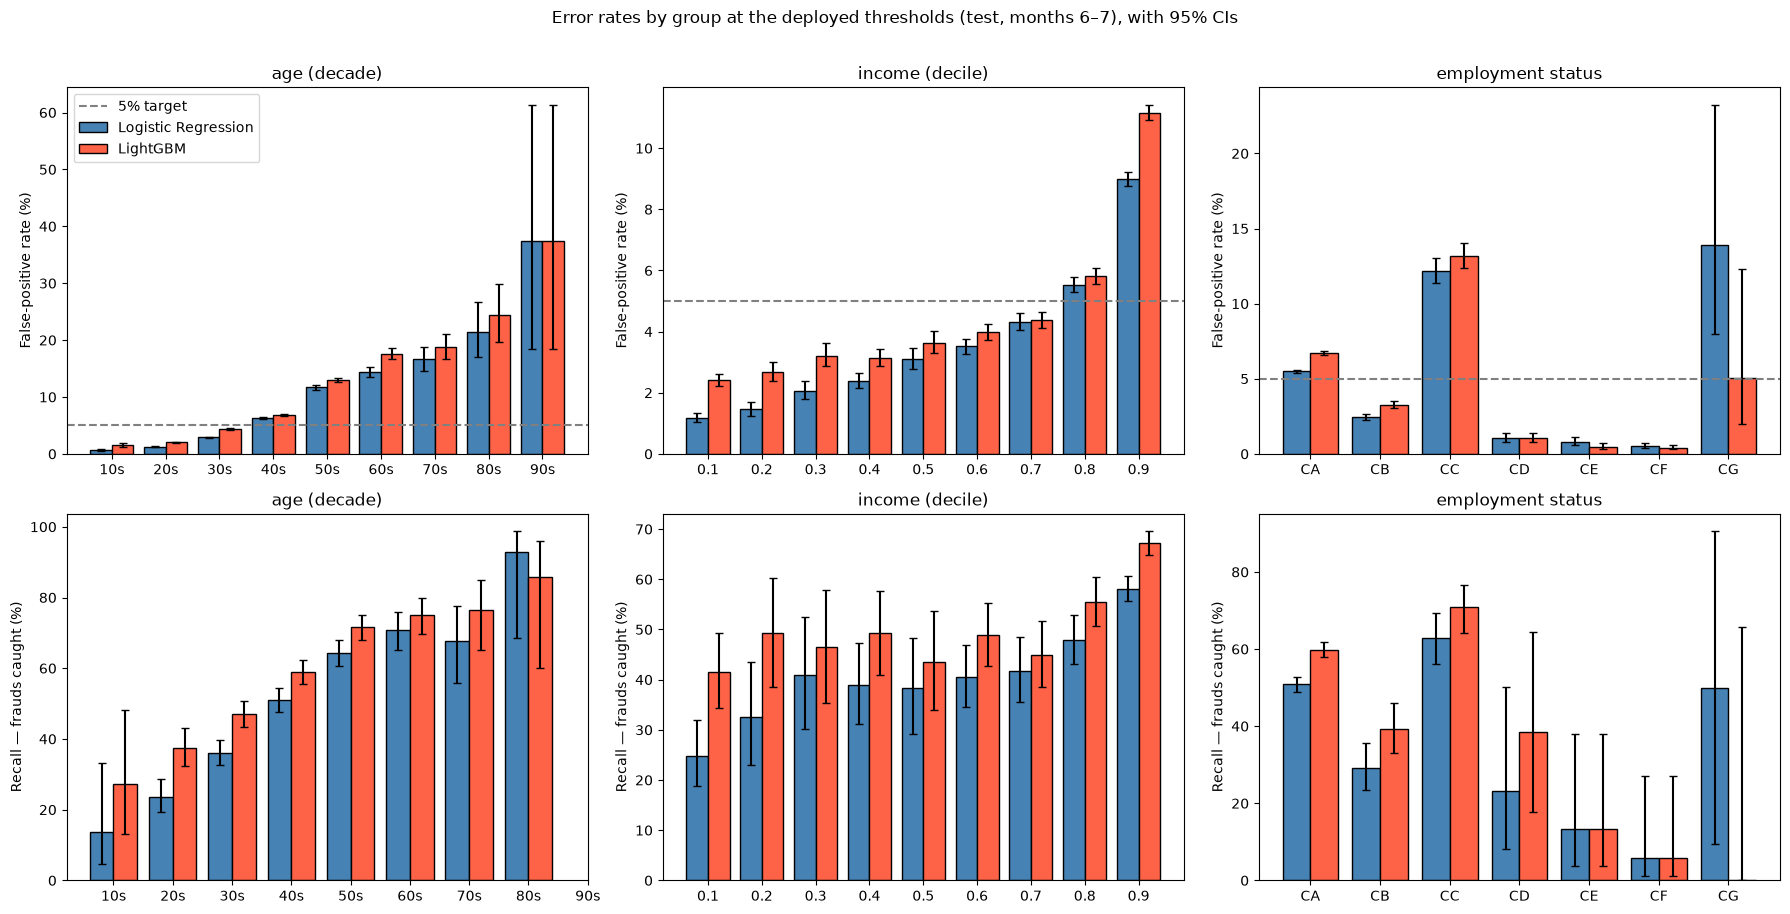

In [5]:
def plot_rates(attr, metric, ax, order=None):
    data = error_rates[error_rates['attribute'] == attr]
    groups = order or sorted(data['group'].unique())
    x = np.arange(len(groups))
    for i, (name, colour) in enumerate([('Logistic Regression', 'steelblue'), ('LightGBM', 'tomato')]):
        d = data[data['model'] == name].set_index('group').loc[groups]
        err = np.vstack([d[metric] - d[f'{metric}_low'], d[f'{metric}_high'] - d[metric]])
        ax.bar(x + (i - 0.5) * 0.4, d[metric] * 100, width=0.4, color=colour, edgecolor='black',
               yerr=err * 100, capsize=3, label=name)
    ax.set_xticks(x)
    ax.set_xticklabels(groups, rotation=0)
    ax.set_title(attr)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for col, attr in enumerate(['age (decade)', 'income (decile)', 'employment status']):
    plot_rates(attr, 'FPR', axes[0, col])
    axes[0, col].axhline(TARGET_FPR * 100, color='grey', linestyle='--', label='5% target')
    axes[0, col].set_ylabel('False-positive rate (%)')
    plot_rates(attr, 'recall', axes[1, col])
    axes[1, col].set_ylabel('Recall — frauds caught (%)')
axes[0, 0].legend()
plt.suptitle('Error rates by group at the deployed thresholds (test, months 6–7), with 95% CIs', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fairness_error_rates_by_group.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Summary fairness metrics
Computed with Fairlearn over groups with at least 1,000 applicants:
- **Demographic parity difference** — largest gap in flag rates between groups (0 = equal).
- **Disparate impact ratio** — lowest flag rate ÷ highest flag rate (1 = equal; below 0.8 fails the common "four-fifths" rule of thumb).
- **Equalised odds difference** — the larger of the gaps in false-positive rate and recall (0 = equal).
- **FPR ratio (predictive equality)** — lowest ÷ highest false-positive rate (1 = equal), the BAF benchmark's fairness measure.
- **FPR difference** and **recall difference** — the raw gaps behind equalised odds.

In [6]:
def fairness_summary(groups, y_true, flag):
    groups = pd.Series(np.asarray(groups))
    sizes = groups.value_counts()
    keep = groups.isin(sizes[sizes >= MIN_GROUP_SIZE].index).to_numpy()
    g, yt, fl = groups[keep].to_numpy(), y_true[keep], flag[keep]
    mf = MetricFrame(metrics={'flag_rate': selection_rate, 'FPR': false_positive_rate, 'recall': true_positive_rate},
                     y_true=yt, y_pred=fl, sensitive_features=g)
    by = mf.by_group
    return {
        'groups_compared': int(len(by)),
        'demographic_parity_difference': demographic_parity_difference(yt, fl, sensitive_features=g),
        'disparate_impact_ratio': demographic_parity_ratio(yt, fl, sensitive_features=g),
        'equalised_odds_difference': equalized_odds_difference(yt, fl, sensitive_features=g),
        'FPR_ratio': mf.ratio()['FPR'],
        'FPR_difference': mf.difference()['FPR'],
        'recall_difference': mf.difference()['recall'],
        'highest_FPR_group': by['FPR'].idxmax(),
        'lowest_FPR_group': by['FPR'].idxmin(),
    }

summary_rows = []
for attr in SUMMARY_ATTRIBUTES:
    for name, model in MODELS.items():
        summary_rows.append({'attribute': attr, 'model': name, **fairness_summary(GROUPS[attr], y, model['flag'])})
fairness = pd.DataFrame(summary_rows).set_index(['attribute', 'model'])
fairness.to_csv(RESULTS_DIR / 'fairness_summary.csv')
fairness.round(3)

groups_compared  \
attribute             model                                  
age (50+ vs under 50) Logistic Regression                2   
                      LightGBM                           2   
age (decade)          Logistic Regression                7   
                      LightGBM                           7   
income (decile)       Logistic Regression                9   
                      LightGBM                           9   
employment status     Logistic Regression                6   
                      LightGBM                           6   

                                           demographic_parity_difference  \
attribute             model                                                
age (50+ vs under 50) Logistic Regression                          0.101   
                      LightGBM                                     0.110   
age (decade)          Logistic Regression                          0.185   
                      LightGBM                                     0.201   
income (decile)       Logistic Regression                          0.089   
                      LightGBM                                     0.099   
employment status     Logistic Regression                          0.132   
                      LightGBM                                     0.145   

                                           disparate_impact_ratio  \
attribute             model                                         
age (50+ vs under 50) Logistic Regression                   0.279   
                      LightGBM                              0.312   
age (decade)          Logistic Regression                   0.038   
                      LightGBM                              0.073   
income (decile)       Logistic Regression                   0.133   
                      LightGBM                              0.215   
employment status     Logistic Regression                   0.038   
                      LightGBM                              0.029   

                                           equalised_odds_difference  \
attribute             model                                            
age (50+ vs under 50) Logistic Regression                      0.264   
                      LightGBM                                 0.226   
age (decade)          Logistic Regression                      0.571   
                      LightGBM                                 0.492   
income (decile)       Logistic Regression                      0.333   
                      LightGBM                                 0.256   
employment status     Logistic Regression                      0.570   
                      LightGBM                                 0.649   

                                           FPR_ratio  FPR_difference  \
attribute             model                                            
age (50+ vs under 50) Logistic Regression      0.282           0.090   
                      LightGBM                 0.314           0.097   
age (decade)          Logistic Regression      0.040           0.159   
                      LightGBM                 0.079           0.173   
income (decile)       Logistic Regression      0.132           0.078   
                      LightGBM                 0.217           0.087   
employment status     Logistic Regression      0.042           0.117   
                      LightGBM                 0.032           0.128   

                                           recall_difference  \
attribute             model                                    
age (50+ vs under 50) Logistic Regression              0.264   
                      LightGBM                         0.226   
age (decade)          Logistic Regression              0.571   
                      LightGBM                         0.492   
income (decile)       Logistic Regression              0.333   
                      LightGBM                         0.256   
employment statu

## 4. Does the disparity depend on the threshold?
The deployed threshold is one choice among many. Here the overall false-positive rate is varied from 1% to 10% (thresholds set on the test data, as in the BAF benchmark), and the age gap is measured at each point. If the gap is similar everywhere, it comes from the model's scores, not from the particular threshold chosen.

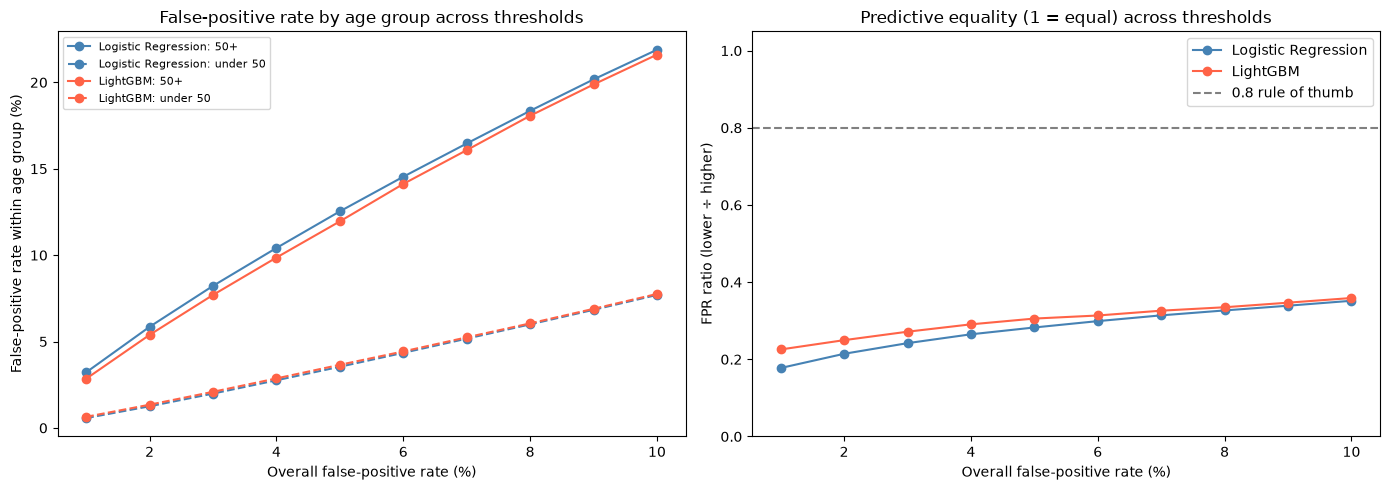

,overall_FPR,FPR_50plus,FPR_under50,FPR_ratio,recall
model,,,,,
Logistic Regression,0.05,0.1253,0.0354,0.2825,0.4958
LightGBM,0.05,0.1195,0.0365,0.3056,0.5479


In [7]:
age50 = GROUPS['age (50+ vs under 50)'].to_numpy()
legit = y == 0
fpr_grid = np.round(np.arange(0.01, 0.105, 0.01), 2)

sweep_rows = []
for name, model in MODELS.items():
    score = model['score']
    for target in fpr_grid:
        thr = np.quantile(score[legit], 1 - target)
        flag = (score >= thr).astype(int)
        fpr_old = flag[legit & (age50 == '50+')].mean()
        fpr_young = flag[legit & (age50 == 'under 50')].mean()
        sweep_rows.append({'model': name, 'overall_FPR': target,
                           'FPR_50plus': fpr_old, 'FPR_under50': fpr_young,
                           'FPR_ratio': min(fpr_old, fpr_young) / max(fpr_old, fpr_young),
                           'recall': flag[y == 1].mean()})
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(RESULTS_DIR / 'fairness_threshold_sweep.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, colour in [('Logistic Regression', 'steelblue'), ('LightGBM', 'tomato')]:
    d = sweep[sweep['model'] == name]
    axes[0].plot(d['overall_FPR'] * 100, d['FPR_50plus'] * 100, '-o', color=colour, label=f'{name}: 50+')
    axes[0].plot(d['overall_FPR'] * 100, d['FPR_under50'] * 100, '--o', color=colour, label=f'{name}: under 50')
    axes[1].plot(d['overall_FPR'] * 100, d['FPR_ratio'], '-o', color=colour, label=name)
axes[0].set_xlabel('Overall false-positive rate (%)')
axes[0].set_ylabel('False-positive rate within age group (%)')
axes[0].set_title('False-positive rate by age group across thresholds')
axes[0].legend(fontsize=8)
axes[1].axhline(0.8, color='grey', linestyle='--', label='0.8 rule of thumb')
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel('Overall false-positive rate (%)')
axes[1].set_ylabel('FPR ratio (lower ÷ higher)')
axes[1].set_title('Predictive equality (1 = equal) across thresholds')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fairness_threshold_sweep.png', dpi=200, bbox_inches='tight')
plt.show()

sweep[sweep['overall_FPR'] == TARGET_FPR].set_index('model').round(4)

## 5. Threshold drift by month and group
In notebook 2, LightGBM's threshold (set on month 5) flagged 6.0% of genuine applicants in the test months instead of 5%. Does that extra harm fall evenly, or on particular groups?

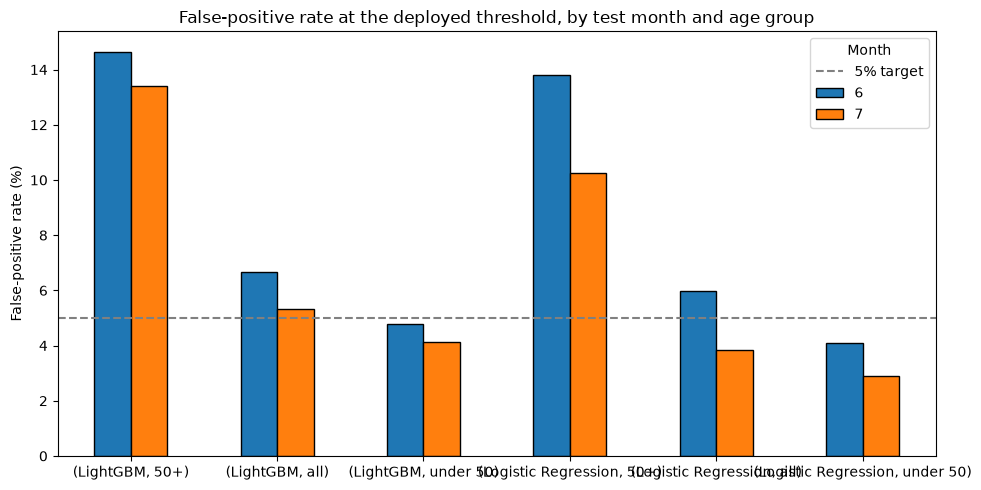

month                              6      7
model               age_group              
LightGBM            50+        14.65  13.40
                    all         6.67   5.31
                    under 50    4.77   4.12
Logistic Regression 50+        13.79  10.25
                    all         5.97   3.85
                    under 50    4.11   2.91

In [8]:
if SPLIT_METHOD == 'temporal':
    test_month = pd.read_parquet(DATA_DIR / 'Base.parquet', columns=['month'])['month'].loc[preds.index].to_numpy()
    drift_rows = []
    for name, model in MODELS.items():
        for month in sorted(np.unique(test_month)):
            for grp in ['under 50', '50+']:
                m = legit & (test_month == month) & (age50 == grp)
                drift_rows.append({'model': name, 'month': int(month), 'age_group': grp,
                                   'genuine_applicants': int(m.sum()), 'FPR': model['flag'][m].mean()})
            m = legit & (test_month == month)
            drift_rows.append({'model': name, 'month': int(month), 'age_group': 'all',
                               'genuine_applicants': int(m.sum()), 'FPR': model['flag'][m].mean()})
    drift = pd.DataFrame(drift_rows)
    drift.to_csv(RESULTS_DIR / 'fairness_drift_by_month.csv', index=False)

    pivot = drift.pivot_table(index=['model', 'age_group'], columns='month', values='FPR')
    ax = (pivot * 100).plot(kind='bar', figsize=(10, 5), edgecolor='black', rot=0)
    ax.axhline(TARGET_FPR * 100, color='grey', linestyle='--', label='5% target')
    ax.set_ylabel('False-positive rate (%)')
    ax.set_xlabel('')
    ax.set_title('False-positive rate at the deployed threshold, by test month and age group')
    ax.legend(title='Month')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'fairness_drift_by_month.png', dpi=200, bbox_inches='tight')
    plt.show()
    display((pivot * 100).round(2))
else:
    print("Random split used in notebook 1, so there are no separate test months to compare.")

## 6. What drives the age gap?
Among **genuine applicants**, the average fraud score (in log-odds) is compared between the 50+ and under-50 groups, and the gap is split into contributions from each feature using the SHAP values from notebook 3. Because SHAP values add up exactly to the score, the bars add up exactly to the total gap.

- If most of the gap comes from `customer_age` itself, removing age from the model should largely close it.
- If much of it comes from **other features**, those features act as **proxies** for age, and simply removing age will not be enough (tested in section 7).

LightGBM: total score gap (50+ minus under 50, genuine applicants) = +0.857 log-odds
   from customer_age itself: +0.392 (46% of the gap)
   from all other features:  +0.464 (54% of the gap)
Logistic Regression: total score gap (50+ minus under 50, genuine applicants) = +0.838 log-odds
   from customer_age itself: +0.462 (55% of the gap)
   from all other features:  +0.376 (45% of the gap)


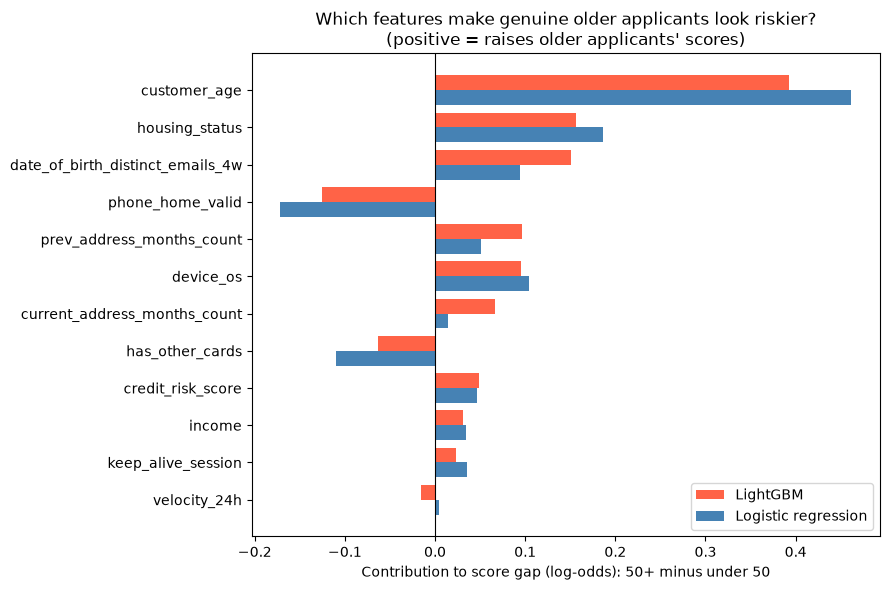

In [9]:
shap_files = {'LightGBM': PROCESSED_DIR / 'shap_lgbm_test.parquet',
              'Logistic Regression': PROCESSED_DIR / 'shap_logreg_test.parquet'}
older, younger = legit & (age50 == '50+'), legit & (age50 == 'under 50')

gap_cols = {}
for name, path in shap_files.items():
    if not path.exists():
        continue
    s = pd.read_parquet(path).loc[preds.index]
    s = s.drop(columns=['base_value'])
    gap_cols[name] = s[older].mean() - s[younger].mean()
    del s
    gc.collect()

gap = pd.DataFrame(gap_cols)
gap['abs'] = gap['LightGBM'].abs()
gap = gap.sort_values('abs', ascending=False).drop(columns='abs')
gap.to_csv(RESULTS_DIR / 'fairness_age_gap_shap_decomposition.csv')

for name in gap.columns:
    total = gap[name].sum()
    direct = gap.loc['customer_age', name]
    print(f"{name}: total score gap (50+ minus under 50, genuine applicants) = {total:+.3f} log-odds")
    if abs(total) >= 0.05:   # percentages are only meaningful when there is a real gap
        print(f"   from customer_age itself: {direct:+.3f} ({direct / total * 100:.0f}% of the gap)")
        print(f"   from all other features:  {total - direct:+.3f} ({(total - direct) / total * 100:.0f}% of the gap)")
    else:
        print(f"   from customer_age itself: {direct:+.3f} | from all other features: {total - direct:+.3f} "
              "(gap too small to split into percentages)")

top = gap.head(12)[::-1]
yy = np.arange(len(top))
plt.figure(figsize=(9, 6))
plt.barh(yy + 0.2, top['LightGBM'], height=0.4, color='tomato', label='LightGBM')
if 'Logistic Regression' in top:
    plt.barh(yy - 0.2, top['Logistic Regression'], height=0.4, color='steelblue', label='Logistic regression')
plt.yticks(yy, top.index)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Contribution to score gap (log-odds): 50+ minus under 50')
plt.title('Which features make genuine older applicants look riskier?\n(positive = raises older applicants\' scores)')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fairness_age_gap_decomposition.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Experiment: retraining without the protected attributes
"Fairness through unawareness": both models are retrained exactly as in notebook 2 (same months, same tuned settings, threshold at 5% FPR on month 5) but **without** age, income and employment status as inputs. The groups are still known, so the audit can be repeated.

If disparities shrink a lot, removing the attributes helps. If they persist, other features are acting as proxies — an important finding, because it means a firm cannot demonstrate fairness simply by not using protected characteristics.

In [10]:
X_train_full = pd.read_parquet(PROCESSED_DIR / 'X_train.parquet')
y_train_full = pd.read_parquet(PROCESSED_DIR / 'y_train.parquet').iloc[:, 0]
X_test = pd.read_parquet(PROCESSED_DIR / 'X_test.parquet').loc[preds.index]
for col in CAT_FEATURES:
    X_test[col] = X_test[col].astype('category').cat.set_categories(X_train_full[col].cat.categories)

# Same validation split as notebook 2
if SPLIT_METHOD == 'temporal':
    months = pd.read_parquet(DATA_DIR / 'Base.parquet', columns=['month'])['month']
    train_months = months.loc[X_train_full.index]
    val_mask = (train_months == train_months.max()).to_numpy()
    del months, train_months
else:
    from sklearn.model_selection import train_test_split
    _, va_idx = train_test_split(np.arange(len(X_train_full)), test_size=0.15,
                                 random_state=RANDOM_STATE, stratify=y_train_full)
    val_mask = np.zeros(len(X_train_full), dtype=bool)
    val_mask[va_idx] = True

FEATURES_NO_PA = [f for f in FEATURES if f not in PROTECTED_ATTRIBUTES]
CAT_NO_PA = [f for f in CAT_FEATURES if f in FEATURES_NO_PA]
NUM_NO_PA = [f for f in NUM_FEATURES if f in FEATURES_NO_PA]

X_tr, y_tr = X_train_full.loc[~val_mask, FEATURES_NO_PA], y_train_full[~val_mask]
X_val, y_val = X_train_full.loc[val_mask, FEATURES_NO_PA], y_train_full[val_mask]
X_te = X_test[FEATURES_NO_PA]
del X_train_full, y_train_full
gc.collect()

print(f"Features without protected attributes: {len(FEATURES_NO_PA)} (removed: {PROTECTED_ATTRIBUTES})")
print("Training:", X_tr.shape, "| Validation:", X_val.shape, "| Test:", X_te.shape)

Features without protected attributes: 26 (removed: ['customer_age', 'income', 'employment_status'])
Training: (675666, 26) | Validation: (119323, 26) | Test: (205011, 26)


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def threshold_at_fpr(y_true, score, target_fpr=TARGET_FPR):
    return float(np.quantile(np.asarray(score)[np.asarray(y_true) == 0], 1 - target_fpr))

def recall_at_fpr(y_true, score, target_fpr=TARGET_FPR):
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(tpr[fpr <= target_fpr].max())

# Logistic regression with the tuned settings from notebook 2
lr_params = thresholds.get('logistic_regression_params', {'C': 1.0, 'class_weight': 'balanced'})
lr_no_pa = Pipeline([
    ('preprocess', ColumnTransformer([
        ('num', StandardScaler(), NUM_NO_PA),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_NO_PA),
    ])),
    ('classifier', LogisticRegression(C=lr_params['C'], class_weight=lr_params['class_weight'],
                                      max_iter=2000, random_state=RANDOM_STATE)),
])
start = time.time()
lr_no_pa.fit(X_tr, y_tr)
print(f"Logistic regression (no protected attributes) trained in {time.time() - start:.1f} s")

# LightGBM with the tuned settings from notebook 2 (early stopping on month 5 again)
lgbm_no_pa = lgb.LGBMClassifier(
    objective='binary', learning_rate=0.05, n_estimators=3000, subsample_freq=1,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **thresholds['lightgbm_params'],
)
if 'eval_X' in inspect.signature(lgb.LGBMClassifier.fit).parameters:
    eval_kwargs = {'eval_X': X_val, 'eval_y': y_val}
else:
    eval_kwargs = {'eval_set': [(X_val, y_val)]}
start = time.time()
lgbm_no_pa.fit(X_tr, y_tr, **eval_kwargs, eval_metric='average_precision',
               callbacks=[lgb.early_stopping(100, verbose=False)])
print(f"LightGBM (no protected attributes) trained in {time.time() - start:.1f} s, trees = {lgbm_no_pa.best_iteration_}")

NO_PA = {}
for name, model in [('Logistic Regression', lr_no_pa), ('LightGBM', lgbm_no_pa)]:
    thr = threshold_at_fpr(y_val, model.predict_proba(X_val)[:, 1])
    score = model.predict_proba(X_te)[:, 1]
    NO_PA[name] = {'score': score, 'flag': (score >= thr).astype(int), 'threshold': thr}

Logistic regression (no protected attributes) trained in 1.4 s
LightGBM (no protected attributes) trained in 8.6 s, trees = 257


In [12]:
rows = []
for version, model_set in [('with protected attributes', MODELS), ('without protected attributes', NO_PA)]:
    for name, m in model_set.items():
        row = {'model': name, 'version': version,
               'AUC-PR': average_precision_score(y, m['score']),
               'Recall@5%FPR': recall_at_fpr(y, m['score']),
               'overall_FPR': m['flag'][legit].mean()}
        for attr in ['age (50+ vs under 50)', 'income (decile)', 'employment status']:
            s = fairness_summary(GROUPS[attr], y, m['flag'])
            row[f'{attr}: FPR ratio'] = s['FPR_ratio']
            row[f'{attr}: equalised odds diff'] = s['equalised_odds_difference']
        rows.append(row)

unawareness = pd.DataFrame(rows).set_index(['model', 'version'])
unawareness.to_csv(RESULTS_DIR / 'fairness_without_protected_attributes.csv')
unawareness.round(3).T

model,Logistic Regression,LightGBM,Logistic Regression,LightGBM
version,with protected attributes,with protected attributes,without protected attributes,without protected attributes
AUC-PR,0.157,0.200,0.147,0.184
Recall@5%FPR,0.496,0.548,0.482,0.539
overall_FPR,0.050,0.060,0.050,0.060
age (50+ vs under 50): FPR ratio,0.282,0.314,0.410,0.446
age (50+ vs under 50): equalised odds diff,0.264,0.226,0.180,0.142
income (decile): FPR ratio,0.132,0.217,0.410,0.504
income (decile): equalised odds diff,0.333,0.256,0.139,0.139
employment status: FPR ratio,0.042,0.032,0.145,0.183
employment status: equalised odds diff,0.570,0.649,0.353,0.482


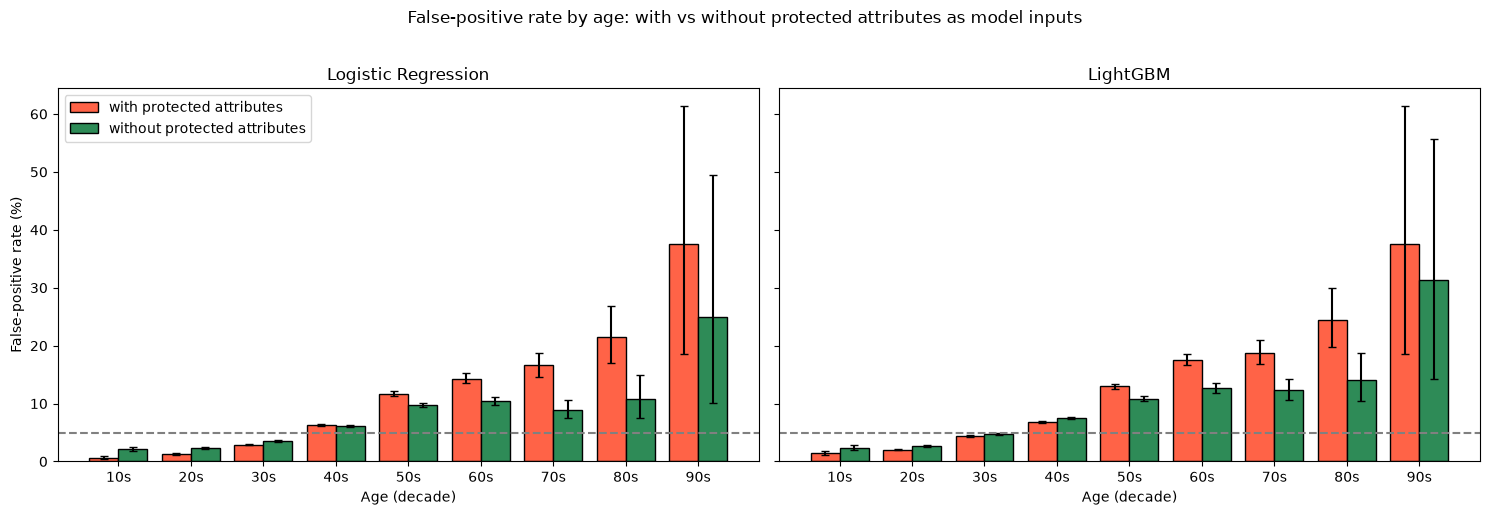

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
groups_age = GROUPS['age (decade)'].to_numpy()
order = sorted(pd.unique(groups_age))
x = np.arange(len(order))
for ax, name in zip(axes, ['Logistic Regression', 'LightGBM']):
    for i, (version, model_set, colour) in enumerate([('with protected attributes', MODELS, 'tomato'),
                                                      ('without protected attributes', NO_PA, 'seagreen')]):
        rates = group_error_rates(groups_age, y, model_set[name]['flag']).loc[order]
        err = np.vstack([rates['FPR'] - rates['FPR_low'], rates['FPR_high'] - rates['FPR']])
        ax.bar(x + (i - 0.5) * 0.4, rates['FPR'] * 100, width=0.4, color=colour, edgecolor='black',
               yerr=err * 100, capsize=3, label=version)
    ax.axhline(TARGET_FPR * 100, color='grey', linestyle='--')
    ax.set_xticks(x)
    ax.set_xticklabels(order)
    ax.set_xlabel('Age (decade)')
    ax.set_title(name)
axes[0].set_ylabel('False-positive rate (%)')
axes[0].legend()
plt.suptitle('False-positive rate by age: with vs without protected attributes as model inputs', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fairness_with_vs_without_protected.png', dpi=200, bbox_inches='tight')
plt.show()

## Save outputs and notes for the write-up
**Caveats to discuss**
- BAF is **synthetic** and its group labels (e.g. employment status "CA") are anonymised, so findings show what this audit framework *can detect*, not real-world discrimination by any firm (as the proposal's ethics section requires).
- Small groups (e.g. the oldest age decades) have wide confidence intervals; conclusions should rest on groups with enough applicants.
- Fairness metrics can conflict with each other and with accuracy. Disagreements between them are a finding to discuss, not a problem to resolve away (Kozodoi, Jacob and Lessmann, 2022).

In [14]:
test_no_pa = pd.DataFrame({
    'lr_noPA_score': NO_PA['Logistic Regression']['score'], 'lr_noPA_flag': NO_PA['Logistic Regression']['flag'],
    'lgbm_noPA_score': NO_PA['LightGBM']['score'], 'lgbm_noPA_flag': NO_PA['LightGBM']['flag'],
}, index=preds.index)
test_no_pa.to_parquet(PROCESSED_DIR / 'test_predictions_without_protected.parquet')
joblib.dump(lgbm_no_pa, MODELS_DIR / 'lightgbm_without_protected.joblib')
joblib.dump(lr_no_pa, MODELS_DIR / 'logistic_regression_without_protected.joblib')

print("Saved:")
for p in sorted(RESULTS_DIR.glob('fairness_*.csv')) + sorted(FIGURES_DIR.glob('fairness_*.png')):
    print("  ", p.relative_to(OUTPUT_DIR.parent))

Saved:
   outputs/results/fairness_age_gap_shap_decomposition.csv
   outputs/results/fairness_drift_by_month.csv
   outputs/results/fairness_error_rates_by_group.csv
   outputs/results/fairness_group_sizes.csv
   outputs/results/fairness_summary.csv
   outputs/results/fairness_threshold_sweep.csv
   outputs/results/fairness_without_protected_attributes.csv
   outputs/figures/fairness_age_gap_decomposition.png
   outputs/figures/fairness_drift_by_month.png
   outputs/figures/fairness_error_rates_by_group.png
   outputs/figures/fairness_threshold_sweep.png
   outputs/figures/fairness_with_vs_without_protected.png
